<a href="https://colab.research.google.com/github/Rishitha0706/landingpage/blob/main/Manuscript_Moisture_Risk_MLOps_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Install dependencies (run this cell first in Google Colab)
%pip -q install numpy pandas scikit-learn matplotlib joblib mlflow fastapi uvicorn httpx pydantic pytest

In [ ]:
# 2. Imports and project folders
import os, json, hashlib, warnings
from pathlib import Path
from datetime import datetime, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

SEED = 42
ROOT = Path('/content/manuscript-moisture-mlops') if Path('/content').exists() else Path.cwd() / 'manuscript-moisture-mlops'
for folder in ['data/v1','data/v2','feature_store','models','reports/figures','docs/screenshots']:
    (ROOT/folder).mkdir(parents=True, exist_ok=True)
print('Project folder:', ROOT)
print('Libraries imported successfully.')

Project folder: /mnt/data/manuscript-moisture-mlops
Libraries imported successfully.


In [ ]:
# 3. Generate reproducible V1 and V2 datasets
RAW_COLUMNS = ['room_id','timestamp','relative_humidity','room_temperature',
 'wall_surface_temperature','door_openings_per_hour','ventilation_duration_min',
 'dehumidifier_hours','room_occupancy','moisture_risk']

def dew_point(temp_c, rh):
    a, b = 17.62, 243.12
    g = np.log(np.clip(rh, 1, 100)/100.0) + a*temp_c/(b+temp_c)
    return b*g/(a-g)

def generate_dataset(version, n=300, seed=42):
    monsoon = version == 'v2'
    rng = np.random.default_rng(seed + (100 if monsoon else 0))
    temp = np.clip(rng.normal(20.5, 2.0, n), 14, 28)
    rh = np.clip(rng.normal(68 if monsoon else 52, 9 if monsoon else 8, n), 30, 95)
    wall_gap = np.abs(rng.normal(2.2 if monsoon else 1.5, 1.2, n))
    wall = temp - wall_gap
    doors = rng.poisson(8 if monsoon else 6, n).astype(float)
    vent = np.clip(rng.normal(120, 40, n), 10, 240)
    if monsoon:
        vent = vent * 0.6
    dehum = np.clip(rng.normal(15 if monsoon else 13, 4, n), 0, 24)
    occ = rng.poisson(3, n).astype(float)
    margin = wall - dew_point(temp, rh)
    z = (0.015*(rh-52) - 0.10*(margin-8.8) + 0.08*(doors-6)
         - 0.006*(vent-120) - 0.08*(dehum-13) + 0.08*(occ-3)
         - 0.75 + rng.normal(0, 0.5, n))
    risk = (z > 0).astype(int)
    start = datetime(2026, 6, 1) if monsoon else datetime(2026, 2, 1)
    df = pd.DataFrame({
      'room_id':[f'ROOM-{i%6+1:02d}' for i in range(n)],
      'timestamp':[(start+timedelta(hours=4*i)).isoformat() for i in range(n)],
      'relative_humidity':rh.round(1),'room_temperature':temp.round(1),
      'wall_surface_temperature':wall.round(1),'door_openings_per_hour':doors,
      'ventilation_duration_min':vent.round(0),'dehumidifier_hours':dehum.round(1),
      'room_occupancy':occ,'moisture_risk':risk})
    for col in ['relative_humidity','wall_surface_temperature','ventilation_duration_min']:
        df.loc[rng.choice(n, size=max(1,n//50), replace=False), col] = np.nan
    return df[RAW_COLUMNS]

manifest = {}
for version, description in [('v1','Normal operating period'),('v2','Monsoon: higher RH and ventilation duration reduced to 60%')]:
    data = generate_dataset(version)
    out = ROOT/f'data/{version}/observations.csv'
    data.to_csv(out,index=False)
    manifest[version] = {'description':description,'path':f'data/{version}/observations.csv',
                         'rows':len(data),'risk_rate':round(float(data.moisture_risk.mean()),4),
                         'sha256':hashlib.sha256(out.read_bytes()).hexdigest()}
    print(f'{version}: {len(data)} records | risk rate: {data.moisture_risk.mean():.1%}')
(ROOT/'data/manifest.json').write_text(json.dumps(manifest,indent=2))
raw_v1 = pd.read_csv(ROOT/'data/v1/observations.csv')
raw_v2 = pd.read_csv(ROOT/'data/v2/observations.csv')
display(pd.DataFrame([{'Version':'V1 – Normal','Records':len(raw_v1),'Mean RH (%)':round(raw_v1.relative_humidity.mean(),1),'Missing sensor values':int(raw_v1.isna().sum().sum())},
 {'Version':'V2 – Monsoon','Records':len(raw_v2),'Mean RH (%)':round(raw_v2.relative_humidity.mean(),1),'Missing sensor values':int(raw_v2.isna().sum().sum())}]))

v1: 300 records | risk rate: 13.3%
v2: 300 records | risk rate: 65.0%


,Version,Records,Mean RH (%),Missing sensor values
0,V1 – Normal,300,52.0,18
1,V2 – Monsoon,300,67.9,18


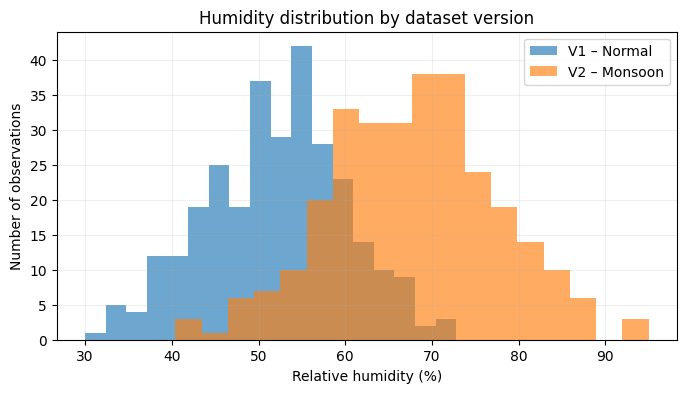

In [ ]:
# 4. Visualize the normal vs monsoon humidity distribution
plt.figure(figsize=(8,4))
plt.hist(raw_v1.relative_humidity.dropna(), bins=18, alpha=.65, label='V1 – Normal')
plt.hist(raw_v2.relative_humidity.dropna(), bins=18, alpha=.65, label='V2 – Monsoon')
plt.xlabel('Relative humidity (%)'); plt.ylabel('Number of observations')
plt.title('Humidity distribution by dataset version'); plt.legend(); plt.grid(alpha=.2); plt.show()

In [ ]:
# 5. Preprocessing, feature engineering and reusable feature store
RAW_FEATURES = ['relative_humidity','room_temperature','wall_surface_temperature',
 'door_openings_per_hour','ventilation_duration_min','dehumidifier_hours','room_occupancy']
ENGINEERED_FEATURES = ['dew_point','condensation_margin','condensation_risk_index','ventilation_effectiveness_ratio']
MODEL_FEATURES = RAW_FEATURES + ENGINEERED_FEATURES
TARGET = 'moisture_risk'
VALID_RANGES = {'relative_humidity':(0,100),'room_temperature':(0,45),
 'wall_surface_temperature':(-5,45),'door_openings_per_hour':(0,200),
 'ventilation_duration_min':(0,1440),'dehumidifier_hours':(0,24),'room_occupancy':(0,100)}

def clean_raw(df):
    df = df.drop_duplicates().copy()
    for col,(lo,hi) in VALID_RANGES.items():
        df = df[df[col].isna() | df[col].between(lo,hi)]
    return df.reset_index(drop=True)

def add_features(df):
    out = df.copy()
    out['dew_point'] = dew_point(out.room_temperature, out.relative_humidity)
    out['condensation_margin'] = out.wall_surface_temperature - out.dew_point
    out['condensation_risk_index'] = (out.relative_humidity/100.0) * (1.0 + np.clip(3.0-out.condensation_margin,0,None))
    out['ventilation_effectiveness_ratio'] = (out.ventilation_duration_min + 5.0*out.dehumidifier_hours) / (1.0+out.door_openings_per_hour+0.5*out.room_occupancy)
    return out

feature_frames = {}
for version in ['v1','v2']:
    source = ROOT/f'data/{version}/observations.csv'
    output = ROOT/f'feature_store/features_{version}.csv'
    if output.exists():
        print(f'[feature store] Reusing saved feature file: {output.name}')
        feat = pd.read_csv(output)
    else:
        print(f'[feature store] Creating features for {version}')
        feat = add_features(clean_raw(pd.read_csv(source)))
        feat['dataset_version'] = version
        feat.to_csv(output,index=False)
    feature_frames[version] = feat
registry = {'versions':{v:{'file':f'features_{v}.csv','rows':len(df),'engineered_features':ENGINEERED_FEATURES} for v,df in feature_frames.items()}}
(ROOT/'feature_store/registry.json').write_text(json.dumps(registry,indent=2))
all_data = pd.concat(feature_frames.values(),ignore_index=True)
print('Combined feature records:',len(all_data))
display(all_data[['relative_humidity','room_temperature','wall_surface_temperature','condensation_risk_index','ventilation_effectiveness_ratio','moisture_risk','dataset_version']].head())

[feature store] Reusing saved feature file: features_v1.csv
[feature store] Reusing saved feature file: features_v2.csv
Combined feature records: 600


,relative_humidity,room_temperature,wall_surface_temperature,condensation_risk_index,ventilation_effectiveness_ratio,moisture_risk,dataset_version
0,65.8,21.1,19.0,0.658,24.000000,0,v1
1,39.7,18.4,17.6,0.397,NaN,0,v1
2,58.9,22.0,19.0,0.589,16.600000,1,v1
3,49.4,22.4,21.6,0.494,20.090909,0,v1
4,51.5,16.6,15.9,0.515,13.764706,0,v1


In [ ]:
# 6. Train both models and compare performance
stratify_key = all_data['dataset_version'].astype(str) + '_' + all_data[TARGET].astype(str)
train_df, test_df = train_test_split(all_data,test_size=.25,random_state=SEED,stratify=stratify_key)
X_train, y_train = train_df[MODEL_FEATURES], train_df[TARGET]
X_test, y_test = test_df[MODEL_FEATURES], test_df[TARGET]

numeric_pipe = Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
preprocessor = ColumnTransformer([('numeric',numeric_pipe,MODEL_FEATURES)])
models = {
 'Decision Tree': DecisionTreeClassifier(max_depth=6,min_samples_leaf=5,class_weight='balanced',random_state=SEED),
 'Random Forest': RandomForestClassifier(n_estimators=300,max_depth=10,min_samples_leaf=3,class_weight='balanced_subsample',random_state=SEED,n_jobs=-1)
}
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
trained, results = {}, {}
for name, classifier in models.items():
    pipe = Pipeline([('preprocessor',preprocessor),('classifier',classifier)])
    cv_scores = cross_validate(pipe,X_train,y_train,cv=cv,scoring=['recall','precision'])
    pipe.fit(X_train,y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:,1]
    tn,fp,fn,tp = confusion_matrix(y_test,pred,labels=[0,1]).ravel()
    results[name] = {'Accuracy':accuracy_score(y_test,pred),
      'Precision (risk)':precision_score(y_test,pred,zero_division=0),
      'Recall (risk)':recall_score(y_test,pred,zero_division=0),
      'F1 (risk)':f1_score(y_test,pred,zero_division=0),
      'ROC-AUC':roc_auc_score(y_test,prob),
      'CV recall mean':cv_scores['test_recall'].mean(),
      'CV precision mean':cv_scores['test_precision'].mean(),
      'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}
    trained[name] = pipe
    print(f"{name}: test recall={results[name]['Recall (risk)']:.3f}, test precision={results[name]['Precision (risk)']:.3f}, CV recall={results[name]['CV recall mean']:.3f}")

eligible = {k:v for k,v in results.items() if v['CV precision mean'] >= .60}
pool = eligible or results
best_name = max(pool,key=lambda k:(pool[k]['CV recall mean'],pool[k]['CV precision mean']))
best_model = trained[best_name]
metrics_df = pd.DataFrame(results).T
print('\nSelected best model:',best_name)
display(metrics_df.round(3))
print('\nClassification report for selected model:')
print(classification_report(y_test,best_model.predict(X_test),target_names=['Acceptable','Moisture Risk']))

Decision Tree: test recall=0.746, test precision=0.710, CV recall=0.727


Random Forest: test recall=0.712, test precision=0.778, CV recall=0.795

Selected best model: Random Forest


,Accuracy,Precision (risk),Recall (risk),F1 (risk),ROC-AUC,CV recall mean,CV precision mean,TN,FP,FN,TP
Decision Tree,0.780,0.710,0.746,0.727,0.808,0.727,0.683,73.0,18.0,15.0,44.0
Random Forest,0.807,0.778,0.712,0.743,0.870,0.795,0.773,79.0,12.0,17.0,42.0



Classification report for selected model:
               precision    recall  f1-score   support

   Acceptable       0.82      0.87      0.84        91
Moisture Risk       0.78      0.71      0.74        59

     accuracy                           0.81       150
    macro avg       0.80      0.79      0.79       150
 weighted avg       0.81      0.81      0.80       150



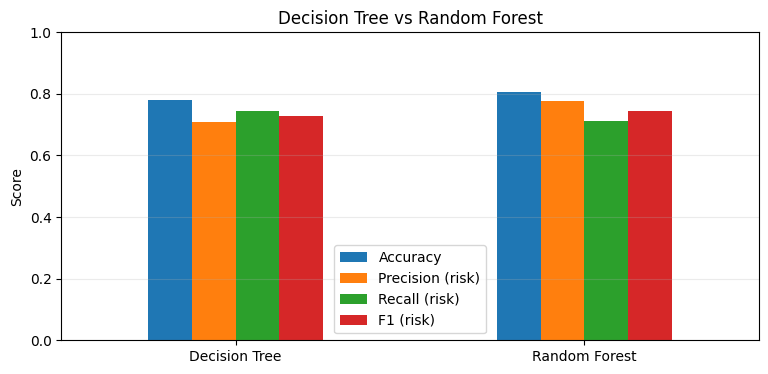

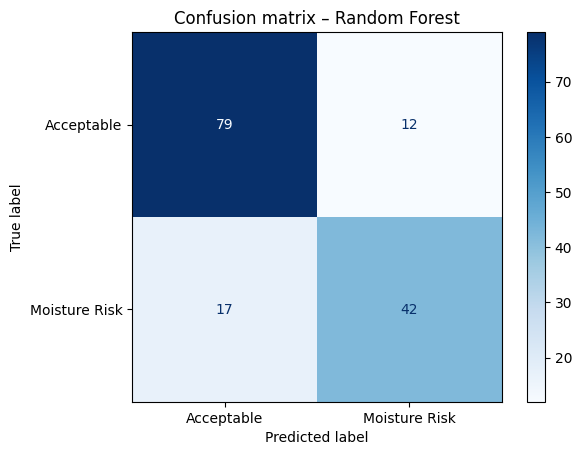

In [ ]:
# 7. Model comparison chart and confusion matrix
metrics_df[['Accuracy','Precision (risk)','Recall (risk)','F1 (risk)']].plot(kind='bar',figsize=(9,4),ylim=(0,1),title='Decision Tree vs Random Forest')
plt.ylabel('Score'); plt.xticks(rotation=0); plt.grid(axis='y',alpha=.25); plt.show()
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(best_model,X_test,y_test,display_labels=['Acceptable','Moisture Risk'],cmap='Blues')
plt.title(f'Confusion matrix – {best_name}'); plt.show()

Saved model: /mnt/data/manuscript-moisture-mlops/models/best_model.joblib
Saved metrics: /mnt/data/manuscript-moisture-mlops/reports/metrics.json


,Importance
condensation_margin,0.187230
ventilation_effectiveness_ratio,0.153715
relative_humidity,0.152943
condensation_risk_index,0.145744
dew_point,0.108036
dehumidifier_hours,0.059420
ventilation_duration_min,0.056508
door_openings_per_hour,0.047293
wall_surface_temperature,0.031048
room_temperature,0.030003


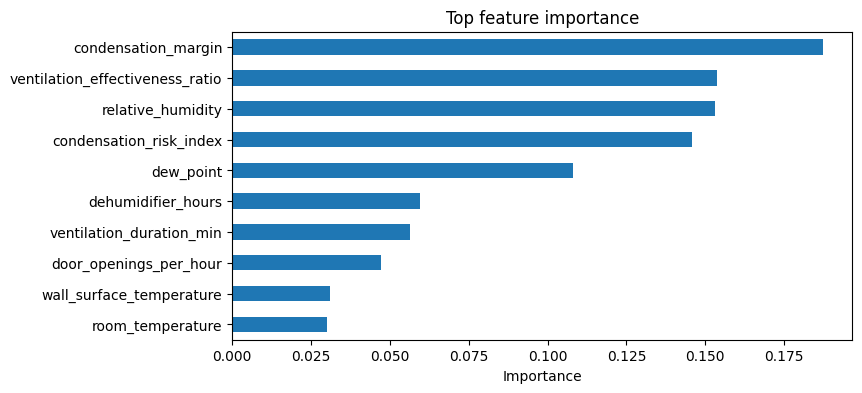

In [ ]:
# 8. Save model, metrics, metadata and feature importance
joblib.dump(best_model,ROOT/'models/best_model.joblib')
summary = {'best_model':best_name,'selection_rule':'Highest 5-fold CV risk recall with CV precision >= 0.60',
           'train_records':len(train_df),'test_records':len(test_df),
           'results':{k:{kk:(float(vv) if isinstance(vv,(np.floating,float)) else int(vv) if isinstance(vv,(np.integer,int)) else vv) for kk,vv in v.items()} for k,v in results.items()}}
(ROOT/'reports/metrics.json').write_text(json.dumps(summary,indent=2))
(ROOT/'models/model_meta.json').write_text(json.dumps({'name':best_name,'features':MODEL_FEATURES},indent=2))
print('Saved model:',ROOT/'models/best_model.joblib')
print('Saved metrics:',ROOT/'reports/metrics.json')

# Feature importance from the fitted tree-based classifier
fitted_clf = best_model.named_steps['classifier']
if hasattr(fitted_clf,'feature_importances_'):
    importance = pd.Series(fitted_clf.feature_importances_,index=MODEL_FEATURES).sort_values(ascending=False)
    display(importance.to_frame('Importance').head(10))
    importance.head(10).sort_values().plot(kind='barh',figsize=(8,4),title='Top feature importance')
    plt.xlabel('Importance'); plt.show()

In [ ]:
# 9. Track experiments and register the selected model with MLflow
try:
    import mlflow, mlflow.sklearn
    from mlflow.models import infer_signature
    mlflow_db = ROOT/'mlflow.db'
    mlflow.set_tracking_uri(f'sqlite:///{mlflow_db}')
    mlflow.set_registry_uri(f'sqlite:///{mlflow_db}')
    mlflow.set_experiment('manuscript-moisture-risk')

    for name, pipe in trained.items():
        with mlflow.start_run(run_name=name) as run:
            mlflow.log_param('model_type',name)
            mlflow.log_param('features',','.join(MODEL_FEATURES))
            mlflow.log_param('dataset_versions','v1,v2')
            for metric_name, value in results[name].items():
                if isinstance(value,(int,float,np.integer,np.floating)):
                    mlflow.log_metric(metric_name,float(value))
            mlflow.log_artifact(str(ROOT/'data/manifest.json'))
            mlflow.log_artifact(str(ROOT/'feature_store/registry.json'))
            if name == best_name:
                signature = infer_signature(X_train,pipe.predict(X_train))
                mlflow.sklearn.log_model(pipe,artifact_path='model',signature=signature,
                    input_example=X_train.head(3),registered_model_name='manuscript-moisture-risk')

    client = mlflow.tracking.MlflowClient()
    versions = client.search_model_versions("name='manuscript-moisture-risk'")
    if versions:
        latest_version = max(int(v.version) for v in versions)
        try:
            client.set_registered_model_alias('manuscript-moisture-risk','champion',str(latest_version))
            alias_status = 'champion'
        except Exception as e:
            alias_status = f'version {latest_version} registered (alias unavailable: {type(e).__name__})'
        print('MLflow experiment: manuscript-moisture-risk')
        print('Registered model: manuscript-moisture-risk')
        print('Model version:',latest_version,'| Alias:',alias_status)
    else:
        print('Runs logged; registry version not returned. Check MLflow UI.')
except ImportError:
    print('MLflow is not installed in this offline preview environment.')
    print('In Google Colab, run the first dependency-installation cell, then rerun this cell to log and register the model.')

MLflow is not installed in this offline preview environment.
In Google Colab, run the first dependency-installation cell, then rerun this cell to log and register the model.


In [ ]:
# 10. Build and test the FastAPI service inside the notebook
from fastapi import FastAPI
from pydantic import BaseModel, Field, ConfigDict
from fastapi.testclient import TestClient

class RoomObservation(BaseModel):
    model_config = ConfigDict(extra='forbid')
    relative_humidity: float = Field(ge=0,le=100)
    room_temperature: float = Field(ge=0,le=45)
    wall_surface_temperature: float = Field(ge=-5,le=45)
    door_openings_per_hour: float = Field(ge=0,le=200)
    ventilation_duration_min: float = Field(ge=0,le=1440)
    dehumidifier_hours: float = Field(ge=0,le=24)
    room_occupancy: float = Field(ge=0,le=100)

api = FastAPI(title='Manuscript Storage Moisture-Risk API',version='1.0')
LABELS = {1:'Moisture Risk',0:'Storage Conditions Acceptable'}
@api.get('/health')
def health():
    return {'status':'ok','model':best_name}
@api.post('/predict')
def predict(obs: RoomObservation):
    row = pd.DataFrame([obs.model_dump()])
    engineered = add_features(row)
    prediction = int(best_model.predict(engineered[MODEL_FEATURES])[0])
    probability = float(best_model.predict_proba(engineered[MODEL_FEATURES])[0,1])
    return {'prediction':LABELS[prediction],'risk_probability':round(probability,4),
      'condensation_risk_index':round(float(engineered.condensation_risk_index.iloc[0]),4),
      'ventilation_effectiveness_ratio':round(float(engineered.ventilation_effectiveness_ratio.iloc[0]),4)}

client = TestClient(api)
print('GET /health')
print(client.get('/health').json())
sample_room = {'relative_humidity':82,'room_temperature':20,'wall_surface_temperature':16,
 'door_openings_per_hour':10,'ventilation_duration_min':45,'dehumidifier_hours':4,'room_occupancy':5}
pred_response = client.post('/predict',json=sample_room)
print('POST /predict – status:',pred_response.status_code)
print(pred_response.json())

GET /health
{'status': 'ok', 'model': 'Random Forest'}
POST /predict – status: 200
{'prediction': 'Moisture Risk', 'risk_probability': 0.9949, 'condensation_risk_index': 3.9617, 'ventilation_effectiveness_ratio': 4.8148}


In [ ]:
# 11. Automated validation tests: endpoint, output labels and invalid sensor readings
checks = []
r = client.get('/health'); checks.append(('Health endpoint',r.status_code==200))
r = client.post('/predict',json=sample_room); checks.append(('Valid prediction',r.status_code==200 and r.json()['prediction'] in LABELS.values()))
bad_rh = {**sample_room,'relative_humidity':125}
r = client.post('/predict',json=bad_rh); checks.append(('Reject RH > 100%',r.status_code==422))
bad_temp = {**sample_room,'room_temperature':60}
r = client.post('/predict',json=bad_temp); checks.append(('Reject temperature > 45 C',r.status_code==422))
for label, passed in checks:
    print(('PASS' if passed else 'FAIL')+' – '+label)
assert all(passed for _,passed in checks)
print(f'\n{sum(p for _,p in checks)}/{len(checks)} notebook API checks passed.')

PASS – Health endpoint
PASS – Valid prediction
PASS – Reject RH > 100%
PASS – Reject temperature > 45 C

4/4 notebook API checks passed.


In [ ]:
# 12. Save a concise project summary and package the project
readme = f"""# Manuscript Moisture Risk MLOps Project

Question 12: Predicting moisture damage risk in rare manuscript storage rooms.

- Synthetic observations: 300 records each for V1 (normal) and V2 (monsoon).
- Engineered features: condensation_risk_index and ventilation_effectiveness_ratio.
- Models: Decision Tree and Random Forest.
- Selected model: {best_name}.
- API endpoints: GET /health and POST /predict.
- Test result: {sum(p for _,p in checks)}/{len(checks)} notebook API checks passed.

Labels are synthetic and are intended for academic demonstration only.
"""
(ROOT/'README.md').write_text(readme)
import shutil
zip_path = shutil.make_archive(str(ROOT.parent/'manuscript-moisture-mlops-colab-project'),'zip',root_dir=ROOT)
print('Project ZIP created:',zip_path)
print('Important files:')
for p in [ROOT/'data/manifest.json',ROOT/'feature_store/registry.json',ROOT/'models/best_model.joblib',ROOT/'reports/metrics.json',ROOT/'mlflow.db']:
    print(('OK' if p.exists() else 'MISSING'),p.name)


Project ZIP created: /mnt/data/manuscript-moisture-mlops-colab-project.zip
Important files:
OK manifest.json
OK registry.json
OK best_model.joblib
OK metrics.json
MISSING mlflow.db
